# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


Мы проверяли, насколько хорошо модель, обученная без меток (DINOv2), понимает картинки. Для этого брали её векторы признаков и проверяли, можно ли по ним простыми методами узнать класс объекта.

## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
# Отдельная подпапка: в artifacts/ лежат результаты лабораторной №1, в artifacts/lab2 и artifacts/lab3 — №2 и №3.
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts/lab4"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT), "artifacts": str(ARTIFACTS)})

{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data', 'artifacts': 'artifacts\\lab4'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Задача 1. Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Разделили данные на train, validation и test поровну по классам.

In [3]:
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

# Профиль вычислений: не более 5 000 изображений суммарно на три выборки.
N_TRAIN, N_VAL, N_TEST = (200, 100, 100) if FAST_DEV_RUN else (3000, 1000, 1000)
IMG_SIZE = 224  # 16x16 патчей по 14 px на входе ViT-S/14
BATCH_SIZE = 128
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def save_json(name, obj):
    """Сохраняет объект в ARTIFACTS/name и возвращает путь."""
    path = ARTIFACTS / name
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")
    return path


_download = not (DATA_ROOT / "cifar-10-batches-py").exists()
cifar_train = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=_download)
cifar_test = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=_download)
CLASSES = cifar_train.classes
y_train_full, y_test_full = np.array(cifar_train.targets), np.array(cifar_test.targets)

# Стратификация: доли классов в каждой выборке те же, что в исходном CIFAR-10.
# Train и validation берутся из обучающей части CIFAR-10, test — только из её тестовой части.
pool_src, _ = train_test_split(np.arange(len(y_train_full)), train_size=N_TRAIN + N_VAL,
                               stratify=y_train_full, random_state=SEED)
train_src, val_src = train_test_split(pool_src, test_size=N_VAL, stratify=y_train_full[pool_src], random_state=SEED)
test_src, _ = train_test_split(np.arange(len(y_test_full)), train_size=N_TEST, stratify=y_test_full, random_state=SEED)
train_src, val_src, test_src = np.sort(train_src), np.sort(val_src), np.sort(test_src)
test_src.setflags(write=False)  # индексы test фиксированы: попытка их изменить вызовет ошибку

# Единый массив изображений: сначала train, затем validation, затем test.
# idx_* — позиции в этом массиве, source_index — индексы в исходных частях CIFAR-10.
images = np.concatenate([cifar_train.data[train_src], cifar_train.data[val_src], cifar_test.data[test_src]])
labels = np.concatenate([y_train_full[train_src], y_train_full[val_src], y_test_full[test_src]])
source_index = np.concatenate([train_src, val_src, test_src])
idx_train = np.arange(0, N_TRAIN)
idx_val = np.arange(N_TRAIN, N_TRAIN + N_VAL)
idx_test = np.arange(N_TRAIN + N_VAL, N_TRAIN + N_VAL + N_TEST)
for _idx in (idx_train, idx_val, idx_test):
    _idx.setflags(write=False)


class CifarArray(Dataset):
    """Изображения CIFAR-10 из массива uint8 [N, 32, 32, 3]: тензор после transform и метка класса."""

    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.labels[i])


# Детерминированная предобработка без аугментаций: признаки одного изображения всегда одинаковы.
eval_transform = T.Compose([
    T.Resize(IMG_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
ds = CifarArray(images, labels, eval_transform)
loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

split = {
    "seed": SEED, "fast_dev_run": FAST_DEV_RUN, "classes": CLASSES,
    "sizes": {"train": len(idx_train), "validation": len(idx_val), "test": len(idx_test)},
    "class_counts": {name: np.bincount(labels[idx], minlength=len(CLASSES)).tolist()
                     for name, idx in (("train", idx_train), ("validation", idx_val), ("test", idx_test))},
    "cifar_train_indices": {"train": train_src.tolist(), "validation": val_src.tolist()},
    "cifar_test_indices": {"test": test_src.tolist()},
}
save_json("split.json", split)

print({"train": len(idx_train), "validation": len(idx_val), "test": len(idx_test), "total": len(ds)})
print("объектов на класс (min, max):", {k: (min(v), max(v)) for k, v in split["class_counts"].items()})
check(len(ds) <= 5000, "суммарно не более 5 000 изображений")
check(len(np.intersect1d(train_src, val_src)) == 0, "train и validation не пересекаются")
check(all(max(v) - min(v) <= 1 for v in split["class_counts"].values()), "классы сбалансированы во всех трёх выборках")
check(tuple(ds[0][0].shape) == (3, IMG_SIZE, IMG_SIZE), f"вход encoder имеет размер 3x{IMG_SIZE}x{IMG_SIZE}")

{'train': 3000, 'validation': 1000, 'test': 1000, 'total': 5000}
объектов на класс (min, max): {'train': (300, 300), 'validation': (100, 100), 'test': (100, 100)}
✔ суммарно не более 5 000 изображений
✔ train и validation не пересекаются
✔ классы сбалансированы во всех трёх выборках
✔ вход encoder имеет размер 3x224x224


### Задача 2. Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


DINOv2 — это предобученная нейросеть от Meta AI (2023), которая превращает изображение в вектор признаков. Она училась без меток классов, то есть в режиме self-supervised learning.

Frozen encoder — это предобученная модель-кодировщик, веса которой зафиксированы и при обучении не меняются. Она только превращает входные данные в признаки, а обучается то, что стоит поверх неё.

Прогнали все 5 000 картинок через замороженную DINOv2 и получили для каждой вектор из 384 чисел.

In [4]:
from transformers import AutoModel

DINO_CHECKPOINT = "facebook/dinov2-small"  # DINOv2 ViT-S/14


class DinoEncoder(nn.Module):
    """DINOv2 ViT-S/14: изображения [B, 3, H, W] -> CLS-токен после финальной LayerNorm [B, 384]."""

    name = "dinov2_vits14"

    def __init__(self):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(DINO_CHECKPOINT)

    def forward(self, x):
        return self.backbone(pixel_values=x).pooler_output

    def last_blocks(self, n):
        """Последние n transformer-блоков и финальная нормализация — часть, которую дообучает адаптация."""
        return [*self.backbone.encoder.layer[-n:], self.backbone.layernorm]


class ResNetEncoder(nn.Module):
    """Fallback из профиля вычислений: ResNet18 (ImageNet) без классификатора, признаки [B, 512]."""

    name = "resnet18"

    def __init__(self):
        super().__init__()
        self.backbone = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        self.backbone.fc = nn.Identity()

    def forward(self, x):
        return self.backbone(x)

    def last_blocks(self, n):
        return [self.backbone.layer4]


def build_encoder():
    """Замороженный encoder в режиме eval: основной вариант — DINOv2, при недоступности весов — ResNet18."""
    try:
        encoder = DinoEncoder()
    except Exception as error:  # нет сети или весов DINOv2
        print(f"DINOv2 недоступен ({type(error).__name__}: {error}) — используется fallback ResNet18")
        encoder = ResNetEncoder()
    return encoder.to(DEVICE).eval().requires_grad_(False)


@torch.no_grad()
def extract_features(encoder, loader):
    """L2-нормированные признаки [N, D] float32 в порядке loader. Метки из loader не используются."""
    encoder.eval()
    feats = []
    for x, _ in loader:
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):  # FP16
            z = encoder(x.to(DEVICE))
        feats.append(F.normalize(z.float(), dim=1).cpu())
    return torch.cat(feats).numpy()


def cached_features(path, encoder, tag):
    """Признаки всего ds из файла path, если он посчитан тем же encoder (tag) на тех же изображениях; иначе пересчёт.

    Возвращает (X, из_кэша). Вместе с признаками сохраняются метки и явные индексы train/validation/test.
    """
    if path.exists():
        with np.load(path) as saved:
            if str(saved["encoder"]) == tag and np.array_equal(saved["source_index"], source_index) \
                    and np.array_equal(saved["idx_test"], idx_test):
                return saved["X"], True
    X = extract_features(encoder, loader)
    np.savez(path, X=X, y=labels, idx_train=idx_train, idx_val=idx_val, idx_test=idx_test,
             source_index=source_index, encoder=tag)
    return X, False


encoder = build_encoder()
start = time.perf_counter()
X, from_cache = cached_features(ARTIFACTS / "embeddings.npz", encoder, encoder.name)
y = labels
print({"encoder": encoder.name, "params_M": round(sum(p.numel() for p in encoder.parameters()) / 1e6, 2),
       "X": X.shape, "dtype": str(X.dtype), "from_cache": from_cache, "seconds": round(time.perf_counter() - start, 1)})
check(encoder.name == DinoEncoder.name, "использован основной encoder DINOv2 ViT-S/14, а не fallback")
check(not any(p.requires_grad for p in encoder.parameters()), "encoder заморожен: обучаемых параметров нет")
check(X.shape[0] == len(ds) and np.isfinite(X).all(), "признаки посчитаны для всех изображений и конечны")
check(np.allclose(np.linalg.norm(X, axis=1), 1.0, atol=1e-4), "признаки L2-нормированы")

c:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 223/223 [00:00<00:00, 2360.86it/s]


{'encoder': 'dinov2_vits14', 'params_M': 22.06, 'X': (5000, 384), 'dtype': 'float32', 'from_cache': True, 'seconds': 0.0}
✔ использован основной encoder DINOv2 ViT-S/14, а не fallback
✔ encoder заморожен: обучаемых параметров нет
✔ признаки посчитаны для всех изображений и конечны
✔ признаки L2-нормированы


### Задача 3. Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


По validation подобрали k для k-NN (k=5) и регуляризацию C для linear probe (C=10)

Работа k-NN
1. Берет картинку из validation
2. Ищет 5 самых близких к ней картинок из train
3. Смотрит на их метки и голосует. 4 кошки и одна собака дают ответ "кошка"
4. Сравнивает с настоящей меткой этой validation-картинки
5. Повторяется для всех 1 000 картинок validation и получается точноть

Регуляризация C у логистической регрессия logistic regression
| C|Регуляризация|Что происходит| 
| :---|:---|:---|
| маленькое (0,1)|сильная|веса маленькие, модель простая, может недообучиться| 
| большое (100)|слабая|модель сильно подстраивается под train, может переобучиться| 

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier

K_GRID = (1, 3, 5, 10, 20, 50)


def fit_knn(X_fit, y_fit, k):
    """k-NN по косинусному расстоянию; k ограничено числом обучающих объектов."""
    return KNeighborsClassifier(n_neighbors=min(k, len(X_fit)), metric="cosine").fit(X_fit, y_fit)


# k выбирается только по validation: test в этой ячейке не используется.
knn_val = {k: float(accuracy_score(y[idx_val], fit_knn(X[idx_train], y[idx_train], k).predict(X[idx_val])))
           for k in K_GRID}
best_k = max(knn_val, key=lambda k: (knn_val[k], -k))  # при равной точности — меньшее k
save_json("knn_val.json", {"val_accuracy": {str(k): round(v, 4) for k, v in knn_val.items()}, "best_k": best_k})

for k, acc in knn_val.items():
    print(f"k={k:>2}: validation accuracy = {acc:.4f}" + ("  <- best_k" if k == best_k else ""))
check(knn_val[best_k] > 1.5 / len(CLASSES), "k-NN на validation заметно лучше случайного угадывания")

k= 1: validation accuracy = 0.9480
k= 3: validation accuracy = 0.9630
k= 5: validation accuracy = 0.9730  <- best_k
k=10: validation accuracy = 0.9690
k=20: validation accuracy = 0.9610
k=50: validation accuracy = 0.9580
✔ k-NN на validation заметно лучше случайного угадывания


### Задача 4. Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Linear probe — это идея, а логистическая регрессия — один из способов её реализовать.

Linear probe означает: поверх замороженных признаков обучить только линейный классификатор, то есть одну матрицу весов $W$ и смещение $b$, без скрытых слоёв:

$$\text{оценки классов} = Wz + b$$

Оценили оба метода на test.

In [6]:
C_GRID = (0.1, 1.0, 10.0, 100.0)


def fit_linear(X_fit, y_fit, C):
    """Linear probe: мультиномиальная логистическая регрессия поверх замороженных признаков."""
    return LogisticRegression(C=C, max_iter=2000).fit(X_fit, y_fit)


def test_metrics(pred):
    """Accuracy и macro-F1 предсказаний на фиксированном test."""
    return {"accuracy": round(float(accuracy_score(y[idx_test], pred)), 4),
            "macro_f1": round(float(f1_score(y[idx_test], pred, average="macro")), 4)}


# Сила регуляризации linear probe подбирается так же, как k: только по validation.
linear_val = {C: float(accuracy_score(y[idx_val], fit_linear(X[idx_train], y[idx_train], C).predict(X[idx_val])))
              for C in C_GRID}
best_C = max(linear_val, key=lambda C: (linear_val[C], -C))  # при равной точности — более сильная регуляризация

# Оба классификатора обучаются только на train; test используется один раз, после выбора k и C.
knn = fit_knn(X[idx_train], y[idx_train], best_k)
linear = fit_linear(X[idx_train], y[idx_train], best_C)
pred_knn, pred_linear = knn.predict(X[idx_test]), linear.predict(X[idx_test])

wrong = np.nonzero(pred_linear != y[idx_test])[0]
probes = {
    "encoder": encoder.name, "n_train": len(idx_train), "n_test": len(idx_test),
    "knn": {"k": best_k, "val_accuracy": round(knn_val[best_k], 4), **test_metrics(pred_knn)},
    "linear": {"C": best_C, "val_accuracy": round(linear_val[best_C], 4),
               "val_accuracy_by_C": {str(C): round(v, 4) for C, v in linear_val.items()}, **test_metrics(pred_linear)},
    "linear_errors": {
        "count": int(len(wrong)),
        "examples": [{"position": int(idx_test[r]), "cifar_test_index": int(source_index[idx_test[r]]),
                      "true": CLASSES[y[idx_test[r]]], "predicted": CLASSES[pred_linear[r]]} for r in wrong[:20]],
    },
}
save_json("probes.json", probes)

for name in ("knn", "linear"):
    print(f"{name:>6}: test accuracy = {probes[name]['accuracy']:.4f}, macro-F1 = {probes[name]['macro_f1']:.4f}")
print({"best_k": best_k, "best_C": best_C, "ошибок linear probe на test": len(wrong)})
check(min(probes["knn"]["accuracy"], probes["linear"]["accuracy"]) > 1.5 / len(CLASSES),
      "оба классификатора на test заметно лучше случайного угадывания")

   knn: test accuracy = 0.9510, macro-F1 = 0.9510
linear: test accuracy = 0.9650, macro-F1 = 0.9651
{'best_k': 5, 'best_C': 10.0, 'ошибок linear probe на test': 35}
✔ оба классификатора на test заметно лучше случайного угадывания


### Задача 5. Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Linear probe («линейная проба») — это способ проверить качество признаков: поверх замороженного encoder обучают один линейный классификатор и смотрят, какую точность он даёт. Probe здесь значит «зонд», «проверка», то есть это инструмент оценки, а не самостоятельная модель.

Проверили, сколько меток нужно: обучали классификаторы на 1%, 10% и 100% train.<br>10% размеченных меток уже дают хорошую точность

In [7]:
FRACTIONS = (0.01, 0.1, 1.0)
SUBSET_SEEDS = tuple(SEED + i for i in range(5))  # фиксированные seed: малые подмножества дают шумную оценку

per_class_total = int(np.bincount(y[idx_train], minlength=len(CLASSES)).min())


def balanced_subsets(seed):
    """Сбалансированные подмножества train для каждой доли меток: поровну объектов каждого класса.

    Подмножества вложены (1% ⊂ 10% ⊂ 100%): для каждого класса берётся начало одной и той же перестановки,
    поэтому доли различаются только добавленными метками.
    """
    rng = np.random.default_rng(seed)
    order = [rng.permutation(idx_train[y[idx_train] == c]) for c in range(len(CLASSES))]
    subsets = {}
    for fraction in FRACTIONS:
        n = max(1, int(round(fraction * per_class_total)))
        subsets[fraction] = np.sort(np.concatenate([o[:n] for o in order]))
    return subsets


# Признаки и гиперпараметры (best_C, best_k) фиксированы, меняется только число размеченных объектов.
runs = {fraction: {"linear": [], "knn": []} for fraction in FRACTIONS}
for seed in SUBSET_SEEDS:
    for fraction, subset in balanced_subsets(seed).items():
        k = min(best_k, len(subset) // len(CLASSES))  # k не больше числа объектов одного класса
        runs[fraction]["linear"].append(accuracy_score(y[idx_test], fit_linear(X[subset], y[subset], best_C).predict(X[idx_test])))
        runs[fraction]["knn"].append(accuracy_score(y[idx_test], fit_knn(X[subset], y[subset], k).predict(X[idx_test])))

label_curve = []
for fraction in FRACTIONS:
    per_class = max(1, int(round(fraction * per_class_total)))
    row = {"fraction": fraction, "n_labeled": per_class * len(CLASSES), "per_class": per_class,
           "knn_k": min(best_k, per_class), "seeds": list(SUBSET_SEEDS)}
    for name in ("linear", "knn"):
        acc = np.array(runs[fraction][name])
        row[f"{name}_test_accuracy"] = round(float(acc.mean()), 4)
        row[f"{name}_test_accuracy_std"] = round(float(acc.std()), 4)
        row[f"{name}_test_accuracy_by_seed"] = [round(float(a), 4) for a in acc]
    label_curve.append(row)
save_json("label_curve.json", {"encoder": encoder.name, "linear_C": best_C, "n_test": len(idx_test), "curve": label_curve})

for row in label_curve:
    print(f"{row['fraction']:>5.0%} меток ({row['n_labeled']:>4} объектов): "
          f"linear = {row['linear_test_accuracy']:.4f} ± {row['linear_test_accuracy_std']:.4f}, "
          f"k-NN (k={row['knn_k']}) = {row['knn_test_accuracy']:.4f} ± {row['knn_test_accuracy_std']:.4f}")
check(label_curve[-1]["n_labeled"] == len(idx_train), "доля 100% совпадает с полным train")
check(abs(label_curve[-1]["linear_test_accuracy"] - probes["linear"]["accuracy"]) < 1e-4,
      "точность при 100% меток совпадает с linear probe из probes.json")

   1% меток (  30 объектов): linear = 0.8424 ± 0.0205, k-NN (k=3) = 0.7782 ± 0.0323
  10% меток ( 300 объектов): linear = 0.9410 ± 0.0053, k-NN (k=5) = 0.9208 ± 0.0092
 100% меток (3000 объектов): linear = 0.9650 ± 0.0000, k-NN (k=5) = 0.9510 ± 0.0000
✔ доля 100% совпадает с полным train
✔ точность при 100% меток совпадает с linear probe из probes.json


### Задача 6. Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Две аугментации - это не две разные операции. Одна и та же случайная цепочка применяется к картинке дважды, и получаются две разные версии (views):
1. Случайный кроп: вырезается 40–100% площади и растягивается обратно до 32×32.
2. Отражение по горизонтали с вероятностью 50%.
3. Изменение цвета (яркость, контраст, насыщенность, оттенок) с вероятностью 80%.
4. Перевод в оттенки серого с вероятностью 20%.

Оптимизируется функция потерь InfoNCE. Её минимизируют две группы параметров: 2 последних блока encoder и небольшая projection head. Принцип такой:
1. Позитивная пара: два view одной картинки, их векторы нужно сблизить.
2. Негативы: все остальные картинки в батче, от них векторы нужно отдалить. При батче 64 на каждый view приходится 126 негативов.


Что такое view
```
исходная картинка собаки
   ├─ view 1: кроп морды, отражение по горизонтали
   └─ view 2: кроп всей собаки, чёрно-белая
```
На обоих изображена одна собака, но пиксели разные. Поэтому view и нужны: сеть должна выдать похожие векторы для двух view одной картинки, а значит, ориентироваться на содержание, а не на цвет или положение объекта.

Немного дообучаем DINOv2 на картинках без меток
1. Сделали копию encoder
2. Разморозили 2 последних блока. 3.55 млн параметра из 22 млн
3. Из каждой train картинки сделали два view
4. Пропустили оба view через encoder и projection head - маленькая сеть, нужная только для расчета loss. Она сжимает вектор с 384 чисел до 128. Используется как фильтр убирает ненужную  часть аугментаций, чтобы модедль лучше понимала основные черты содержимого объекта и меньше уделяла вниманию на яркость пикселей и обрезку картинки.
5. Минимизировали InfoNCE. Векторы двух view одной картинки сближаютсю, а векторы разных отдаляются. Меток при этом нет
6. Сохранили обновленный encoder, а head выбросили.

Loss снизился с 1.93 до 1.41, а случайному угадыванию соответствует 4.84. Encoder действительно чему-то научился.

Процесс расчета loss (4, 5 шаг)
1. Берём 64 картинки и из каждой делаем два view
2. DINO выдает векторы для всех 128 view
3. Код проверяет для каждого вектора на сколько он близок к своей паре и насколько к остальным 126
4. Выставляется оценка loss. Если пара ближе всех остальных, loss маленький. Если ближе оказался чужой вектор, loss большой
5. Через backpropagation веса DINO немного подкручиваются, чтобы в следующий раз пары были ближе, а чужие - дальше

Projection head сжимает вектор с 384 чисел до 128. 

In [8]:
import copy

ADAPT = {
    "epochs": 1 if FAST_DEV_RUN else 5,
    "batch_size": 16 if FAST_DEV_RUN else 64,
    "temperature": 0.2,
    "unfrozen_blocks": 2,   # дообучаются только последние блоки encoder, остальные остаются замороженными
    "proj_dim": 128,
    "lr_encoder": 1e-5,
    "lr_head": 1e-3,
    "weight_decay": 0.05,
}
adapt_tag = json.dumps({**ADAPT, "encoder": encoder.name, "n_train": len(idx_train), "seed": SEED}, sort_keys=True)

# Аугментации выполняются на исходном разрешении 32x32, затем view приводится ко входу encoder.
augment = T.Compose([
    T.RandomResizedCrop(32, scale=(0.4, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
    T.RandomGrayscale(p=0.2),
    T.Resize(IMG_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class TwoViews(Dataset):
    """Две независимые аугментации одного изображения. Метки классов в датасет не передаются."""

    def __init__(self, images, transform):
        self.images, self.transform = images, transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        image = Image.fromarray(self.images[i])
        return self.transform(image), self.transform(image)


def info_nce(z1, z2, temperature):
    """InfoNCE (NT-Xent) для батча пар: позитив объекта i — второй view того же изображения,
    негативы — остальные 2B-2 представления батча; сам объект из знаменателя исключён."""
    z = F.normalize(torch.cat([z1, z2]).float(), dim=1)
    sim = (z @ z.T / temperature).masked_fill(torch.eye(len(z), dtype=torch.bool, device=z.device), float("-inf"))
    targets = torch.arange(len(z), device=z.device).roll(len(z1))  # i <-> i + B
    return F.cross_entropy(sim, targets)


def load_state(path):
    """Сохранённое состояние адаптации, если файл есть и получен с текущей конфигурацией; иначе None."""
    if not path.exists():
        return None
    state = torch.load(path, map_location=DEVICE)
    return state if state["config"] == adapt_tag else None


# Адаптируется копия: исходный encoder остаётся нетронутым для сравнения до/после.
adapted = copy.deepcopy(encoder)
adapt_params = [p for module in adapted.last_blocks(ADAPT["unfrozen_blocks"]) for p in module.parameters()]
for p in adapt_params:
    p.requires_grad_(True)
# Projection head нужен только для loss: в encoder_adapted.pt он не входит, признаки берутся до него.
head = nn.Sequential(nn.Linear(X.shape[1], X.shape[1]), nn.GELU(), nn.Linear(X.shape[1], ADAPT["proj_dim"])).to(DEVICE)
optimizer = torch.optim.AdamW([{"params": adapt_params, "lr": ADAPT["lr_encoder"]},
                               {"params": head.parameters(), "lr": ADAPT["lr_head"]}], weight_decay=ADAPT["weight_decay"])
scaler = torch.amp.GradScaler(DEVICE, enabled=DEVICE == "cuda")
views_loader = DataLoader(TwoViews(images[idx_train], augment), batch_size=ADAPT["batch_size"],
                          shuffle=True, drop_last=True, num_workers=0)

final_path, ckpt_path = ARTIFACTS / "encoder_adapted.pt", ARTIFACTS / "ckpt_contrastive.pt"
start_epoch, history = 0, []
if (state := load_state(final_path)) is not None:
    # Адаптация с этой конфигурацией уже завершена: повторный запуск ячейки её не пересчитывает.
    adapted.load_state_dict(state["encoder"])
    start_epoch, history = ADAPT["epochs"], state["history"]
    print(f"загружен готовый {final_path.name}")
elif (state := load_state(ckpt_path)) is not None:
    # Обучение было прервано: продолжаем со следующей эпохи после сохранённой.
    adapted.load_state_dict(state["encoder"]); head.load_state_dict(state["head"])
    optimizer.load_state_dict(state["optimizer"]); scaler.load_state_dict(state["scaler"])
    start_epoch, history = state["epoch"], state["history"]
    print(f"продолжение с эпохи {start_epoch + 1}")

# Encoder остаётся в eval: dropout в нём нет, а статистики BatchNorm (fallback ResNet18) не должны сдвигаться.
adapted.eval()
for epoch in range(start_epoch, ADAPT["epochs"]):
    torch.manual_seed(SEED + epoch)  # перемешивание и аугментации эпохи не зависят от того, был ли перезапуск
    losses, t0 = [], time.perf_counter()
    for v1, v2 in views_loader:
        x = torch.cat([v1, v2]).to(DEVICE)
        with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=DEVICE == "cuda"):
            z = head(adapted(x))
        loss = info_nce(z[:len(v1)], z[len(v1):], ADAPT["temperature"])  # считается в FP32
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.item())
    history.append({"epoch": epoch + 1, "steps": len(losses), "loss": round(float(np.mean(losses)), 4),
                    "seconds": round(time.perf_counter() - t0, 1)})
    print(history[-1])
    torch.save({"config": adapt_tag, "epoch": epoch + 1, "history": history, "encoder": adapted.state_dict(),
                "head": head.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict()}, ckpt_path)

adapted.requires_grad_(False)
total_steps = sum(h["steps"] for h in history)
# Контрольная сумма весов различает разные обученные encoder с одной конфигурацией (для кэша признаков).
adapt_checksum = round(float(sum(p.double().sum() for p in adapt_params)), 6)
torch.save({"config": adapt_tag, "history": history, "optimizer_steps": total_steps, "checksum": adapt_checksum,
            "encoder": adapted.state_dict()}, final_path)

shift = max(float((a - b).abs().max()) for a, b in zip(adapted.parameters(), encoder.parameters()))
print({"optimizer_steps": total_steps, "trainable_params_M": round(sum(p.numel() for p in adapt_params) / 1e6, 2),
       "max_weight_shift": shift, "loss_first_epoch": history[0]["loss"], "loss_last_epoch": history[-1]["loss"],
       "loss_at_chance": round(float(np.log(2 * ADAPT["batch_size"] - 1)), 4)})
check(total_steps > 0 and shift > 0, "выполнены реальные optimizer steps: веса encoder изменились")
check(all(np.isfinite(h["loss"]) for h in history), "loss конечен на всех эпохах")

загружен готовый encoder_adapted.pt
{'optimizer_steps': 230, 'trainable_params_M': 3.55, 'max_weight_shift': 0.00173187255859375, 'loss_first_epoch': 1.9288, 'loss_last_epoch': 1.4083, 'loss_at_chance': 4.8442}
✔ выполнены реальные optimizer steps: веса encoder изменились
✔ loss конечен на всех эпохах


### Задача 7. Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Пересчитали признаки обновленным encoder всех 5 000 картинок и обучили на них новый linear probe (логистическая регресия). Точность на validation осталась на том же уровне, разница 0.2 п.п. - всего 2 картинки из 1 000.

In [9]:
# Те же изображения, та же предобработка и тот же порядок, что у исходных признаков: меняется только encoder.
start = time.perf_counter()
X_new, from_cache = cached_features(ARTIFACTS / "embeddings_adapted.npz", adapted,
                                    f"{encoder.name}+infonce|{adapt_tag}|{adapt_checksum}")

# Новый linear probe обучается только на train с тем же C, что и исходный: сравнение контролируемое.
new_linear = fit_linear(X_new[idx_train], y[idx_train], best_C)
new_val_accuracy = float(accuracy_score(y[idx_val], new_linear.predict(X_new[idx_val])))

# Насколько адаптация сдвинула представления: косинус между старым и новым признаком одного изображения.
cos_old_new = (X * X_new).sum(axis=1)
print({"X_new": X_new.shape, "from_cache": from_cache, "seconds": round(time.perf_counter() - start, 1),
       "C": best_C, "val_accuracy_original": round(linear_val[best_C], 4), "val_accuracy_adapted": round(new_val_accuracy, 4),
       "cos(old, new) mean": round(float(cos_old_new.mean()), 4), "cos(old, new) min": round(float(cos_old_new.min()), 4)})
check(X_new.shape == X.shape and np.isfinite(X_new).all(), "X_new посчитана для тех же изображений, что и X")
check(not np.allclose(X_new, X), "признаки после адаптации отличаются от исходных")

{'X_new': (5000, 384), 'from_cache': True, 'seconds': 0.2, 'C': 10.0, 'val_accuracy_original': 0.98, 'val_accuracy_adapted': 0.978, 'cos(old, new) mean': 0.9204, 'cos(old, new) min': 0.6871}
✔ X_new посчитана для тех же изображений, что и X
✔ признаки после адаптации отличаются от исходных


| | Encoder | Признаки | Probe |
|---|---|---|---|
| Было (задача 4) | исходный DINOv2 | `X` | `linear`, обучен на `X` |
| Стало (задача 7) | адаптированный | `X_new` | `new_linear`, обучен с нуля на `X_new` |

### Задача 8. Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Сравнение accuracy до и после адаптации, но уже на test.<br>
Разница в 0.4 п.п. - это 4 картинки. Исправила 9 ошибок, но испортила 5 верных ответов. 95% доверительный интервал разницы [−0,3; +1,2] п.п. Он включает ноль, поэтому улучшение не доказано.

In [10]:
# Парное сравнение: оба probe оцениваются на одних и тех же test-объектах.
y_te = y[idx_test]
pred_old, pred_new = linear.predict(X[idx_test]), new_linear.predict(X_new[idx_test])
pred_knn_new = fit_knn(X_new[idx_train], y[idx_train], best_k).predict(X_new[idx_test])
old_ok, new_ok = pred_old == y_te, pred_new == y_te

# Доверительный интервал разности accuracy — бутстреп по test-объектам (разность парная).
rng = np.random.default_rng(SEED)
diff = new_ok.astype(float) - old_ok.astype(float)
boot = diff[rng.integers(0, len(diff), (10_000, len(diff)))].mean(axis=1)

adaptation = {
    "encoder": encoder.name, "n_test": len(idx_test), "linear_C": best_C, "knn_k": best_k,
    "linear_probe": {"original": test_metrics(pred_old), "adapted": test_metrics(pred_new)},
    "knn": {"original": test_metrics(pred_knn), "adapted": test_metrics(pred_knn_new)},
    "linear_accuracy_delta": round(float(diff.mean()), 4),
    "linear_accuracy_delta_ci95": [round(float(np.percentile(boot, 2.5)), 4), round(float(np.percentile(boot, 97.5)), 4)],
    "paired": {"fixed_by_adaptation": int((~old_ok & new_ok).sum()), "broken_by_adaptation": int((old_ok & ~new_ok).sum()),
               "both_correct": int((old_ok & new_ok).sum()), "both_wrong": int((~old_ok & ~new_ok).sum())},
    "adaptation_config": ADAPT, "optimizer_steps": total_steps, "loss_history": history,
}
save_json("adaptation.json", adaptation)

for name in ("linear_probe", "knn"):
    print(f"{name:>12}: accuracy {adaptation[name]['original']['accuracy']:.4f} -> {adaptation[name]['adapted']['accuracy']:.4f}")
print({"delta": adaptation["linear_accuracy_delta"], "ci95": adaptation["linear_accuracy_delta_ci95"], **adaptation["paired"]})
check(adaptation["linear_probe"]["original"]["accuracy"] == probes["linear"]["accuracy"],
      "исходный probe оценён на том же test, что и в probes.json")

linear_probe: accuracy 0.9650 -> 0.9690
         knn: accuracy 0.9510 -> 0.9620
{'delta': 0.004, 'ci95': [-0.003, 0.012], 'fixed_by_adaptation': 9, 'broken_by_adaptation': 5, 'both_correct': 960, 'both_wrong': 26}
✔ исходный probe оценён на том же test, что и в probes.json


Что k-NN показывает. Он проверяет, лежат ли изображения одного класса рядом в пространстве признаков. Высокая точность значит, что DINOv2 без всяких меток расположил похожие по смыслу картинки близко. Linear probe проверяет другое — можно ли разделить классы плоскостями.

### Задача 9. Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Для каждой test картинки нашли 5 самых похожих картинки из train, чтобы посмотреть, кого DINO  считает близкими.

d = 1 - cos<br>0 - векторы смотрят в одну сторону, 1 - перпендикулярны

Грузовик и все пять соседей грузовики.

In [12]:
N_NEIGHBORS = 5


def nearest_train(features, k=N_NEIGHBORS):
    """Для каждого test-объекта — k ближайших train-объектов по косинусному расстоянию.

    Признаки L2-нормированы, поэтому расстояние равно 1 - скалярное произведение.
    Возвращает позиции соседей в ds [n_test, k] и расстояния [n_test, k], от ближнего к дальнему.
    """
    sim = features[idx_test] @ features[idx_train].T
    order = np.argsort(-sim, axis=1)[:, :k]
    return idx_train[order], 1.0 - np.take_along_axis(sim, order, axis=1)


# Запросы фиксированы: все объекты test в порядке idx_test. Соседи ищутся в исходных признаках DINO.
nn_pos, nn_dist = nearest_train(X)
nn_labels = y[nn_pos]

queries = [{
    "query_position": int(q), "query_cifar_test_index": int(source_index[q]), "query_label": CLASSES[y[q]],
    "neighbor_positions": nn_pos[r].tolist(), "neighbor_cifar_train_indices": source_index[nn_pos[r]].tolist(),
    "neighbor_labels": [CLASSES[c] for c in nn_labels[r]], "distances": [round(float(d), 4) for d in nn_dist[r]],
} for r, q in enumerate(idx_test)]
save_json("neighbors.json", {"encoder": encoder.name, "metric": "cosine", "k": N_NEIGHBORS,
                             "n_queries": len(queries), "queries": queries})

for row in queries[:5]:
    print(f"test #{row['query_cifar_test_index']:>4} {row['query_label']:>10} -> {row['neighbor_labels']}  d = {row['distances']}")
print({"среднее расстояние до 1-го соседа": round(float(nn_dist[:, 0].mean()), 4),
       "до 5-го": round(float(nn_dist[:, -1].mean()), 4)})
check(nn_pos.shape == (len(idx_test), N_NEIGHBORS) and np.isin(nn_pos, idx_train).all(), "все соседи взяты из train")
check((np.diff(nn_dist, axis=1) >= 0).all(), "соседи упорядочены от ближнего к дальнему")

test #   5       frog -> ['frog', 'frog', 'frog', 'frog', 'frog']  d = [0.4272, 0.4393, 0.4565, 0.4586, 0.4744]
test #  23      truck -> ['truck', 'truck', 'truck', 'truck', 'truck']  d = [0.2311, 0.2727, 0.2886, 0.2921, 0.2965]
test #  28      truck -> ['truck', 'truck', 'truck', 'truck', 'truck']  d = [0.3191, 0.3273, 0.3282, 0.3383, 0.3542]
test #  29       frog -> ['frog', 'frog', 'frog', 'frog', 'frog']  d = [0.3289, 0.3489, 0.37, 0.3762, 0.3882]
test #  34      truck -> ['truck', 'truck', 'truck', 'truck', 'truck']  d = [0.2586, 0.2841, 0.2885, 0.2921, 0.3033]
{'среднее расстояние до 1-го соседа': 0.3635, 'до 5-го': 0.4369}
✔ все соседи взяты из train
✔ соседи упорядочены от ближнего к дальнему


d - косинусное расстояние. 0 - векторы смотрят в одну сторону, 1 - векторы перпендикулярны (ничего общего)

Для каждой из 1000 test-картинок нашли 5 ближайших соседей из train.<br>
В задаче 10 для каждой test-картинки посчитали долю соседей своего класса, то есть чистоту

### Задача 10. Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Проверяем, насколько однородно окружение каждой test картинки, то есть сколько из её 5 соседей (найденных в задаче 9) того же класса.

1. Чистота каждого запроса — доля соседей своего класса: 5 из 5 = 1,0, 3 из 5 = 0,6, 0 из 5 = 0.
2. Средняя чистота по всем 1000 test-картинкам. 0.922
3. Средняя чистота после адаптации 0.936
4. Все пять соседей из своего класса 814 из 1000
5. Все пять соседей чужие 11 из 1000
6. Хуждшие классы кошка 0.812 и собака 0.844
7. Лучшие классы лошадь 0.966 и корабль 0.964
8. Самая часта пара смешиваний собака -> кошка     63 раза
9. Распределение: сколько картинок с чистотой 0; 0,2; … ; 1,0.
10. Чистота по классам — где окружение самое смешанное.
11. Частые пары смешения — какой класс чаще всего попадает в соседи к другому.
12. 10 худших примеров — запросы с минимальной чистотой.
13. Та же средняя чистота на адаптированных признаках — для сравнения.

In [13]:
from collections import Counter

# Чистота окрестности запроса — доля его пяти соседей с тем же классом, что у запроса.
y_te = y[idx_test]
purity = (nn_labels == y_te[:, None]).mean(axis=1)
# Худшие запросы: минимальная чистота, при равенстве — меньшее расстояние (уверенно близкие объекты чужого класса).
worst_rows = np.lexsort((nn_dist.mean(axis=1), purity))

# Какие пары классов смешиваются: (класс запроса, класс соседа) среди несовпадающих соседей.
mixed = Counter((CLASSES[q], CLASSES[n]) for q, row in zip(y_te, nn_labels) for n in row if n != q)
# Та же метрика в признаках после контрастивной адаптации — для сравнения локальной структуры.
purity_new = (y[nearest_train(X_new)[0]] == y_te[:, None]).mean(axis=1)

neighborhood_purity = {
    "encoder": encoder.name, "k": N_NEIGHBORS, "n_queries": len(purity),
    "mean_purity": round(float(purity.mean()), 4),
    "mean_purity_adapted": round(float(purity_new.mean()), 4),
    "share_fully_pure": round(float((purity == 1).mean()), 4),
    "share_majority_wrong": round(float((purity < 0.5).mean()), 4),
    "purity_histogram": {f"{v:.1f}": int(np.isclose(purity, v).sum()) for v in np.linspace(0, 1, N_NEIGHBORS + 1)},
    "mean_purity_by_class": {name: round(float(purity[y_te == c].mean()), 4) for c, name in enumerate(CLASSES)},
    "top_mixed_pairs": [{"query": q, "neighbor": n, "count": c} for (q, n), c in mixed.most_common(10)],
    "lowest_purity_examples": [{
        "query_position": int(idx_test[r]), "query_cifar_test_index": int(source_index[idx_test[r]]),
        "query_label": CLASSES[y_te[r]], "purity": round(float(purity[r]), 2),
        "neighbor_labels": [CLASSES[c] for c in nn_labels[r]], "distances": [round(float(d), 4) for d in nn_dist[r]],
        "linear_probe_prediction": CLASSES[pred_linear[r]],
    } for r in worst_rows[:10]],
}
save_json("neighborhood_purity.json", neighborhood_purity)

print({k: neighborhood_purity[k] for k in ("mean_purity", "mean_purity_adapted", "share_fully_pure", "share_majority_wrong")})
print("распределение чистоты:", neighborhood_purity["purity_histogram"])
print("чистота по классам:", neighborhood_purity["mean_purity_by_class"])
print("чаще всего смешиваются:", [(p["query"], p["neighbor"], p["count"]) for p in neighborhood_purity["top_mixed_pairs"][:5]])
print("запросы с минимальной чистотой:")
for row in neighborhood_purity["lowest_purity_examples"]:
    print(f"  test #{row['query_cifar_test_index']:>4} {row['query_label']:>10} purity={row['purity']:.1f} -> {row['neighbor_labels']}"
          f"  (linear probe: {row['linear_probe_prediction']})")
check(0.0 <= purity.min() and purity.max() <= 1.0, "чистота лежит в [0, 1]")
check(abs(purity.mean() - (nn_labels == y_te[:, None]).mean()) < 1e-9, "средняя чистота посчитана по тем же пяти соседям")

{'mean_purity': 0.922, 'mean_purity_adapted': 0.936, 'share_fully_pure': 0.814, 'share_majority_wrong': 0.059}
распределение чистоты: {'0.0': 11, '0.2': 16, '0.4': 32, '0.6': 48, '0.8': 79, '1.0': 814}
чистота по классам: {'airplane': 0.936, 'automobile': 0.958, 'bird': 0.892, 'cat': 0.812, 'deer': 0.942, 'dog': 0.844, 'frog': 0.944, 'horse': 0.966, 'ship': 0.964, 'truck': 0.962}
чаще всего смешиваются: [('dog', 'cat', 63), ('cat', 'dog', 41), ('cat', 'deer', 23), ('cat', 'frog', 20), ('frog', 'cat', 19)]
запросы с минимальной чистотой:
  test #3787        cat purity=0.0 -> ['deer', 'deer', 'deer', 'deer', 'deer']  (linear probe: deer)
  test #7784      horse purity=0.0 -> ['deer', 'deer', 'frog', 'frog', 'frog']  (linear probe: frog)
  test #2299       frog purity=0.0 -> ['cat', 'cat', 'cat', 'dog', 'cat']  (linear probe: cat)
  test # 862        cat purity=0.0 -> ['deer', 'deer', 'deer', 'deer', 'frog']  (linear probe: deer)
  test #4661       deer purity=0.0 -> ['cat', 'cat', 'cat',

mean_purity — средняя чистота окрестности: какая доля ближайших соседей в среднем принадлежит тому же классу, что и сама картинка.

### Задача 11. Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Из худших примеров 10 задачи взяли две test-картинки, у которых все 5 соседей чужого класса. У каждого примера чистота 0, то есть все соседи из другого класса. Попробуем посмотреть на картинки и понять, почему DINO их перепутал, то есть найти визуальное объяснение.<br>
На первом коллаже кошка. Светлое животное стоит в профиль на тёмном лесном фоне. Олени-соседи выглядят так же: светло-коричневый окрас, похожая поза, зелень вокруг. При размере 32×32 ушей и морды почти не разобрать, и форма с окрасом совпадают.<br>
На втором коллаже лошадь. Тёмный силуэт на пёстром коричнево-зелёном фоне. Соседи — олени и лягушки на таком же природном фоне. Самой лошади в них нет, сходство в основном в фоне и цвете.

Часть ошибок DINO объясняется shortcut features — «короткими путями»: когда деталей объекта мало, модель опирается на фон, цвет и силуэт, а не на сам объект.

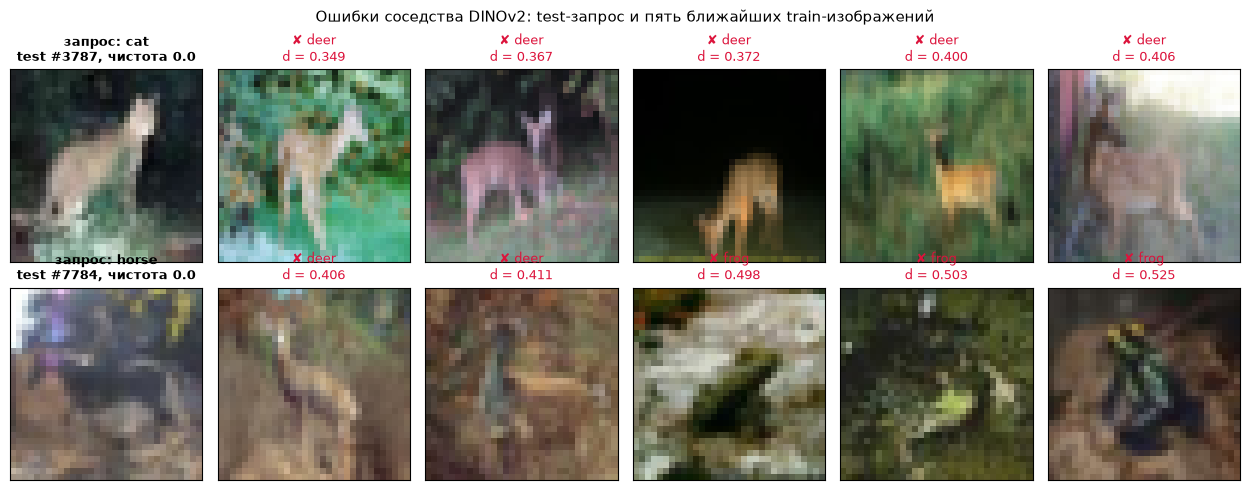

test #3787 cat (чистота 0.0, linear probe: deer) -> train [49098, 10834, 27647, 3970, 1557] ['deer', 'deer', 'deer', 'deer', 'deer']
test #7784 horse (чистота 0.0, linear probe: frog) -> train [49237, 16222, 10510, 26885, 6755] ['deer', 'deer', 'frog', 'frog', 'frog']
✔ выбраны два запроса со смешанной окрестностью
✔ коллаж сохранён в bonus_neighbors.png


In [14]:
import matplotlib.pyplot as plt

# Два запроса с минимальной чистотой (порядок worst_rows из прошлой ячейки) из разных классов,
# чтобы коллаж показывал два разных типа смешения, а не два одинаковых случая.
bonus_rows = []
for r in worst_rows:
    if all(y_te[r] != y_te[b] for b in bonus_rows):
        bonus_rows.append(int(r))
    if len(bonus_rows) == 2:
        break

fig, axes = plt.subplots(len(bonus_rows), N_NEIGHBORS + 1, figsize=(2.1 * (N_NEIGHBORS + 1), 2.5 * len(bonus_rows)))
for i, r in enumerate(bonus_rows):
    q = idx_test[r]
    axes[i, 0].imshow(images[q], interpolation="nearest")  # исходные 32x32 без сглаживания
    axes[i, 0].set_title(f"запрос: {CLASSES[y[q]]}\ntest #{source_index[q]}, чистота {purity[r]:.1f}", fontsize=9, fontweight="bold")
    for j in range(N_NEIGHBORS):
        n = nn_pos[r, j]
        same = y[n] == y[q]
        axes[i, j + 1].imshow(images[n], interpolation="nearest")
        axes[i, j + 1].set_title(f"{'✔' if same else '✘'} {CLASSES[y[n]]}\nd = {nn_dist[r, j]:.3f}", fontsize=9,
                                 color="black" if same else "crimson")
    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Ошибки соседства DINOv2: test-запрос и пять ближайших train-изображений", fontsize=11)
fig.tight_layout()
fig.savefig(ARTIFACTS / "bonus_neighbors.png", dpi=150, bbox_inches="tight")
plt.show()

bonus = [{
    "query_position": int(idx_test[r]), "query_cifar_test_index": int(source_index[idx_test[r]]),
    "query_label": CLASSES[y_te[r]], "purity": round(float(purity[r]), 2),
    "linear_probe_prediction": CLASSES[pred_linear[r]],
    "neighbor_positions": nn_pos[r].tolist(), "neighbor_cifar_train_indices": source_index[nn_pos[r]].tolist(),
    "neighbor_labels": [CLASSES[c] for c in nn_labels[r]], "distances": [round(float(d), 4) for d in nn_dist[r]],
} for r in bonus_rows]
save_json("bonus_neighbors.json", {"encoder": encoder.name, "image": "bonus_neighbors.png", "queries": bonus})

for row in bonus:
    print(f"test #{row['query_cifar_test_index']} {row['query_label']} (чистота {row['purity']}, linear probe: "
          f"{row['linear_probe_prediction']}) -> train {row['neighbor_cifar_train_indices']} {row['neighbor_labels']}")
check(len(bonus_rows) == 2 and all(purity[r] < 1 for r in bonus_rows), "выбраны два запроса со смешанной окрестностью")
check((ARTIFACTS / "bonus_neighbors.png").exists(), "коллаж сохранён в bonus_neighbors.png")

## Анализ результатов

Все числа ниже получены в полном режиме (`FAST_DEV_RUN=False`) и взяты из файлов в `artifacts/lab4`. Test — 1 000 изображений из тестовой части CIFAR-10 (по 100 на класс); он не использовался ни для подбора k и C, ни при адаптации.

### Бюджет

| Параметр | Значение |
|---|---|
| Данные | 5 000 изображений CIFAR-10: train 3 000 / validation 1 000 / test 1 000, классы сбалансированы |
| Encoder | DINOv2 ViT-S/14 (`facebook/dinov2-small`), 22,06 млн параметров, FP16, вход 224×224 |
| Признаки | CLS-токен, 384 числа, L2-нормирован; извлечение для всех 5 000 изображений — около 12 с |
| Адаптация | 2 последних блока + финальная LayerNorm (3,55 млн параметров), 5 эпох × 46 шагов = 230 optimizer steps, около 21 с на эпоху |
| Оборудование | NVIDIA GeForce RTX 3060 |

### Frozen-признаки: k-NN и linear probe (`knn_val.json`, `probes.json`)

| Классификатор | Параметр (выбран на validation) | Validation acc. | Test acc. | Test macro-F1 |
|---|---|---|---|---|
| k-NN, косинусное расстояние | k = 5 | 0,973 | 0,951 | 0,951 |
| Linear probe (логистическая регрессия) | C = 10 | 0,980 | 0,965 | 0,965 |

Замороженный encoder, ни разу не видевший меток CIFAR-10, даёт 95–96,5% точности с простыми классификаторами. Linear probe лучше k-NN на 1,4 п.п. Точность на test примерно на 2 п.п. ниже, чем на validation: часть разрыва — оптимизм от выбора k и C по той же validation.

### Кривая объёма разметки (`label_curve.json`)

Признаки и параметры (k, C) зафиксированы, меняется только число меток; подмножества сбалансированы и вложены друг в друга. Указаны среднее и стандартное отклонение по 5 фиксированным seed.

| Меток | На класс | Linear probe | k-NN |
|---|---|---|---|
| 1% (30) | 3 | 0,842 ± 0,021 | 0,778 ± 0,032 (k = 3) |
| 10% (300) | 30 | 0,941 ± 0,005 | 0,921 ± 0,009 |
| 100% (3 000) | 300 | 0,965 | 0,951 |

Трёх размеченных изображений на класс хватает для 84% точности; при 10% меток потеря относительно полного train — 2,4 п.п. Разрыв между linear probe и k-NN растёт при малом числе меток (6,4 п.п. при 1% против 1,4 п.п. при 100%): у k-NN при трёх примерах на класс мало «своих» соседей, а линейная граница обобщает лучше.

### Контрастивная адаптация (`adaptation.json`, `neighborhood_purity.json`)

InfoNCE-loss снизился с 1,93 до 1,41 за 5 эпох (уровень случайного угадывания — 4,84); веса изменились не более чем на 0,0017. Сравнение на одном и том же test с тем же C:

| Метрика | Frozen | После адаптации | Разница |
|---|---|---|---|
| Linear probe, accuracy | 0,965 | 0,969 | +0,4 п.п., 95% ДИ [−0,3; +1,2] |
| k-NN, accuracy | 0,951 | 0,962 | +1,1 п.п. |
| Средняя чистота 5 соседей | 0,922 | 0,936 | +1,4 п.п. |

Парно для linear probe: адаптация исправила 9 ошибок и создала 5 новых, ещё 26 изображений ошибочны в обоих вариантах. Доверительный интервал содержит ноль, поэтому улучшение linear probe не значимо. k-NN и чистота окрестности выросли заметнее. По дополнительному расчёту на сохранённых признаках средняя косинусная близость test-изображения к train-изображениям чужих классов упала с 0,106 до 0,048, а к своему классу почти не изменилась (0,310 → 0,314). Адаптация в основном раздвинула разные классы, а это сильнее сказывается на методе, который работает напрямую с расстояниями.

### Ошибки модели и смешение классов (`probes.json`, `neighborhood_purity.json`, `bonus_neighbors.png`)

- **Ошибки linear probe:** 35 из 1 000. Типичные: dog → cat, truck → automobile, cat → deer, bird → deer, ship → airplane.
- **Чистота окрестности:** в среднем 92,2% соседей того же класса; у 81,4% запросов все пять соседей «свои», у 5,9% большинство соседей чужие.
- **Самые смешанные классы:** cat (0,81), dog (0,84), bird (0,89). Самые чистые — horse (0,97), ship, truck, automobile (около 0,96).
- **Частые пары смешения** (число чужих соседей): dog → cat (63), cat → dog (41), cat → deer (23), cat → frog (20), frog → cat (19), truck ↔ automobile (19 и 18), bird → deer (18).
- **Связь с классификатором:** среди 10 запросов с нулевой чистотой linear probe ошибся на 9 и почти всегда назвал класс соседей. Локальное смешение в пространстве признаков прямо переходит в ошибки: линейный классификатор поверх таких признаков их не исправляет.

**Разбор коллажа** (`bonus_neighbors.png`, `bonus_neighbors.json`):

1. **Cat, test #3787** → все пять соседей deer (расстояния 0,35–0,41), linear probe тоже ответил deer. На изображении светло-коричневое животное в вертикальной позе среди тёмной зелени: силуэт, окрас и лесной фон совпадают с типичными фотографиями оленей из train. При разрешении 32×32 картинка неоднозначна и для человека; не исключена и ошибка разметки CIFAR-10.
2. **Horse, test #7784** → два соседа deer и три frog (расстояния 0,41–0,52), linear probe ответил frog. Лошадь тёмная и занимает малую часть кадра, бо́льшую часть которого занимает пёстрый коричнево-зелёный фон. Соседей объединяет не объект, а фон и текстура: олени на бурой земле и лягушки на пятнистом грунте. Это пример shortcut features — опоры на фон и цветовую гамму вместо формы объекта. Большие расстояния до соседей (до 0,52 при среднем 0,36 до первого соседа по всему test) показывают, что изображение нетипично и плотной окрестности у него нет.

### Контролируемые сравнения (ablation)

- **Объём разметки:** 1% / 10% / 100% меток при фиксированных признаках, k и C и вложенных подмножествах.
- **Адаптация encoder:** frozen и адаптированный encoder на тех же изображениях, том же test и с тем же C; меняется только encoder.
- **Гиперпараметры:** сетки k ∈ {1, 3, 5, 10, 20, 50} и C ∈ {0,1; 1; 10; 100}, выбор только по validation.

### Ограничения

- **Размер выборки.** Использовано 5 000 из 60 000 изображений CIFAR-10. На 1 000 test-изображений стандартная ошибка accuracy около 0,6 п.п., поэтому различия в 0,4–1,1 п.п. между frozen и адаптированным encoder статистически ненадёжны.
- **Разрешение.** Изображения 32×32 растянуты до 224×224 и размыты, тогда как DINOv2 обучался на фотографиях высокого разрешения. Часть ошибок (cat ↔ deer, horse ↔ frog) вызвана нехваткой деталей на самом изображении.
- **Адаптация не настраивалась.** Проверена одна конфигурация (2 блока, lr 1e-5, τ = 0,2, 5 эпох) в одном запуске; влияние этих параметров и разброс между запусками не измерены. 3 000 изображений и 230 шагов — очень малый бюджет по сравнению с предобучением DINOv2 на 142 млн изображений.
- **1% меток** — это 30 изображений; оценка шумная (±2 п.п. между seed), хотя и усреднена по 5 seed.
- **Признаки.** Используется только CLS-токен; патч-токены и другие способы агрегации не проверялись.
- **Соседи и чистота** посчитаны при одном k = 5 и одной (косинусной) метрике.
- **Разбор ошибок качественный:** объяснения по коллажу — интерпретация двух изображений, а не измеренная зависимость от фона.

## Выводы

1. **Признаки DINOv2 без меток уже разделяют классы CIFAR-10.** Замороженный ViT-S/14 с одним линейным слоем даёт 96,5% точности на test, k-NN — 95,1% (`probes.json`). Классы почти линейно разделимы, а похожие изображения лежат рядом: у 81% test-изображений все пять ближайших соседей того же класса (`neighborhood_purity.json`).

2. **Представление эффективно по числу меток.** При 30 размеченных изображениях (3 на класс) linear probe достигает 84%, при 300 — 94%, то есть 10% разметки теряют всего 2,4 п.п. относительно полного train (`label_curve.json`). При малой разметке linear probe заметно лучше k-NN (84% против 78% при 1% меток), при полной разметке разрыв сокращается до 1,4 п.п.

3. **Короткая контрастивная адаптация почти не меняет качество.** 230 шагов InfoNCE на 3 000 изображениях снизили loss с 1,93 до 1,41, но точность linear probe изменилась на +0,4 п.п. при 95% ДИ [−0,3; +1,2] — улучшение не доказано (`adaptation.json`). Сильнее отреагировали k-NN (+1,1 п.п.) и чистота окрестности (0,922 → 0,936): адаптация раздвинула разные классы, что важнее для методов, работающих с расстояниями.

4. **Ошибки сосредоточены в визуально близких классах.** Хуже всего разделены cat и dog (чистота 0,81 и 0,84; dog → cat — самая частая пара смешения), затем automobile ↔ truck и животные на природном фоне (cat, bird, deer, frog). Там, где окрестность полностью чужая, linear probe ошибается в 9 случаях из 10: ошибки классификатора наследуются из геометрии признаков.

5. **Часть ошибок объясняется shortcut features.** На коллаже (`bonus_neighbors.png`) лошадь на пёстром коричнево-зелёном фоне получает соседей-оленей и лягушек с похожим фоном, а светлая кошка в лесу — пятерых оленей с тем же окрасом и позой. При разрешении 32×32 encoder опирается на фон, цвет и силуэт, когда деталей объекта не хватает.

Итог: для CIFAR-10 в рамках бюджета 5 000 изображений замороженный DINOv2 с linear probe — сильный и дешёвый вариант. Узкое место — не классификатор, а размытые изображения и визуально похожие пары классов; для значимого эффекта адаптации нужны больший test, несколько запусков и подбор её параметров.